<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

# 01_04 Clustering

In this notebook you will practice with K-means and Agglomerative clustering in different settings.


## 1. K-means

### 1.1 Load a custom dataset

We’ll begin with a dataset that has 3 imbalanced clusters that will help us observe that different K-Means runs (different initializations) can produce different clusterings.

**What to do**
1. Create three cluster dataset with the following code:
~~~
X, _ = make_blobs(n_samples=[100, 50, 5], centers=[(0,0), (3,3), (-2,-2)], cluster_std=[0.4, 0.2, 0.1], random_state=42)
~~~
3. Plot a scatter of the points (no labels).
4. We’ll use this dataset to show that K-Means results depend on initialization when the data has no clear structure.



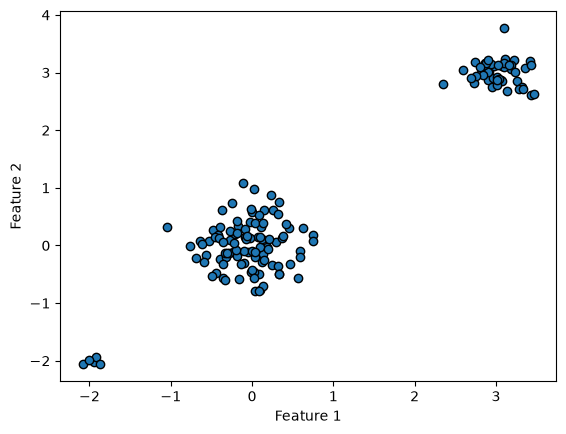

In [1]:
from sklearn.datasets import make_blobs

import matplotlib.pyplot as plt

X, _ = make_blobs(n_samples=[100, 50, 5], centers=[(0,0), (3,3), (-2,-2)], cluster_std=[0.4, 0.2, 0.1], random_state=42)


#3. Plot a scatter of the points (no labels).
plt.scatter(X[:, 0], X[:, 1], edgecolor="k")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### 1.2 K-Means randomness: different runs, different results

K-Means uses random initial centroids so different runs can converge to different local minima.

**What to do**
1. For a fixed `k=3`, run `KMeans` with the appropriate values for parameters `n_init`, `init` and several seeds (0,1,2,3,...), to ensure that the initialiation is different.
2. Plot the cluster assignments and centroids for each run.
3. Record the inertia (`.inertia_`) to compare runs.

**Note:** The inertia, also called the within-cluster sum of squared errors (SSE), is the expression that K-Means tries to minimize:
$$
\text{Inertia} = \sum_{i=1}^n \lVert x_i - \mu_{c(i)} \rVert^2
$$
where $x_i$ is a data point, and $\mu_{c(i)}$ is the centroid of the cluster it belongs to.

- Lower inertia = points are closer to their cluster centroids (tighter clusters).
- Inertia decreases as k increases (more clusters, smaller groups).

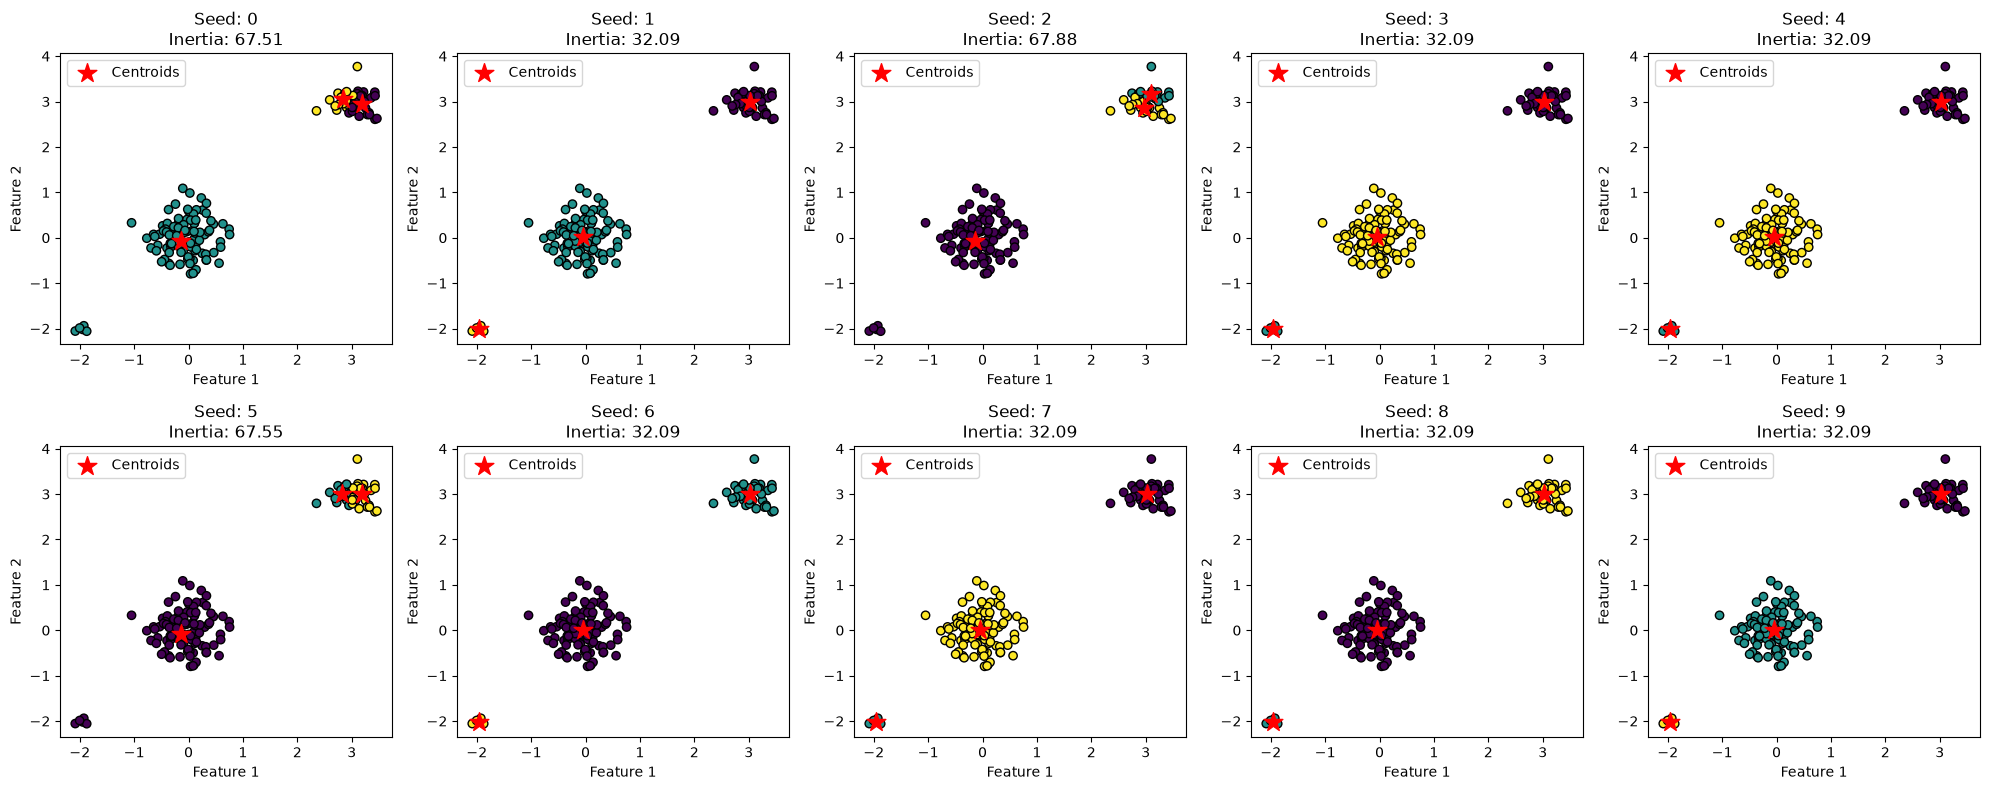

In [2]:
from sklearn.cluster import KMeans

# 1. Run KMeans with different random seeds
k = 3
seeds = range(10)
inertias = []


# 2. Function to plot clusters and centroids
def plot_kmeans(X, kmeans, seed, ax):
    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=kmeans.labels_,
        edgecolor="k",
        cmap="viridis"
    )

    ax.scatter(
        kmeans.cluster_centers_[:, 0],
        kmeans.cluster_centers_[:, 1],
        c="red",
        marker="*",
        s=200,
        label="Centroids"
    )

    ax.set_title(
        f"Seed: {seed}\nInertia: {kmeans.inertia_:.2f}"
    )
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()


# 3. Create subplots
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for i, seed in enumerate(seeds):
    kmeans = KMeans(
        n_clusters=k,
        n_init=1,
        init="random",
        random_state=seed
    )

    kmeans.fit(X)
    inertias.append(kmeans.inertia_)

    plot_kmeans(X, kmeans, seed, axes.flat[i])

plt.tight_layout()
plt.show()

### 1.3 Multiple runs with `n_init`

Instead of running K-Means manually many times, sklearn’s implementation already supports this through the parameter **`n_init`**:

- `n_init` = number of random initializations to try.  
- K-Means will keep the run with the **lowest inertia**.  
- By default, `n_init` is set to 10 in recent versions of sklearn.

**What to do**
1. Run with random initialization and 20 runs.  
2. Fit it on the dataset.  
3. Plot the clusters and centroids.  
4. Compare inertia to the single-run version from the previous step.


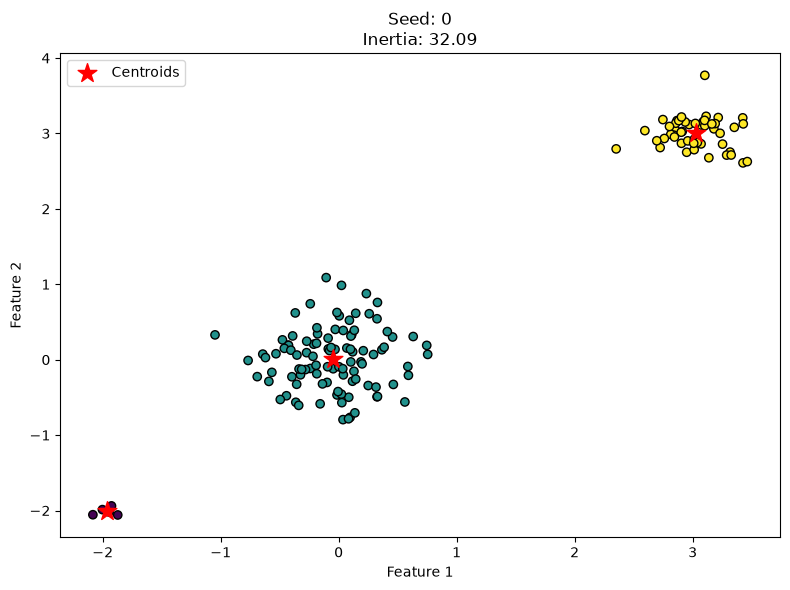

Single-run inertia: 67.51
n_init=20 inertia: 32.09


In [3]:
#1. Run with random initialization and 20 runs. 
kmeans_20 = KMeans(
    n_clusters=k,
    n_init=20,
    init="random",
    random_state=0
)
#2. Fit it on the dataset. 
kmeans_20.fit(X) 
#3. Plot the clusters and centroids.
plt.figure(figsize=(8, 6))

plot_kmeans(X, kmeans_20, 0, plt.gca())

plt.tight_layout()
plt.show()

#4. Compare inertia to the single-run version from the previous step.
print(f"Single-run inertia: {inertias[0]:.2f}")
print(f"n_init=20 inertia: {kmeans_20.inertia_:.2f}")


### 1.4 Load a simple 2D dataset (blobs)

Let's move to a dataset where K-Means should do well: isotropic Gaussian blobs.

**What to do**
1. Generate blobs with `make_blobs(n_samples=800, centers=3, cluster_std=1.1, random_state=7)`.
2. Plot a scatter of the points.


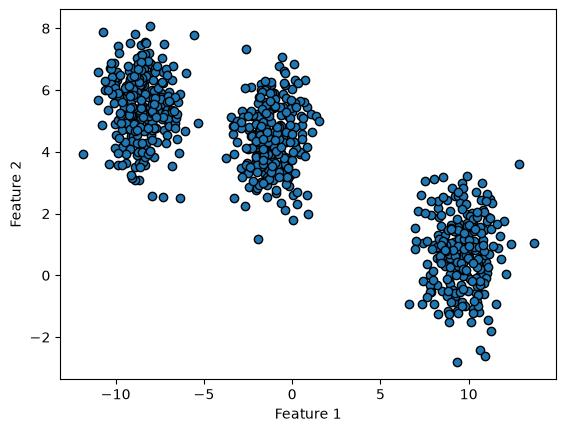

In [4]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

# 1. Generate the dataset
X, _ = make_blobs(
    n_samples=800,
    centers=3,
    cluster_std=1.1,
    random_state=7
)

# 2. Plot the points
plt.scatter(
    X[:, 0],
    X[:, 1],
    edgecolor="k"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### 1.5 Varying the number of clusters `k`

Let’s see how results change with **different k**.

**What to do**
1. For `k` in a small range (e.g., 1..8), run K-Means with multiple initializations.
2. Plot inertia vs k.
3. Visualize clustering for a couple of k values (e.g., k=2,3,4).


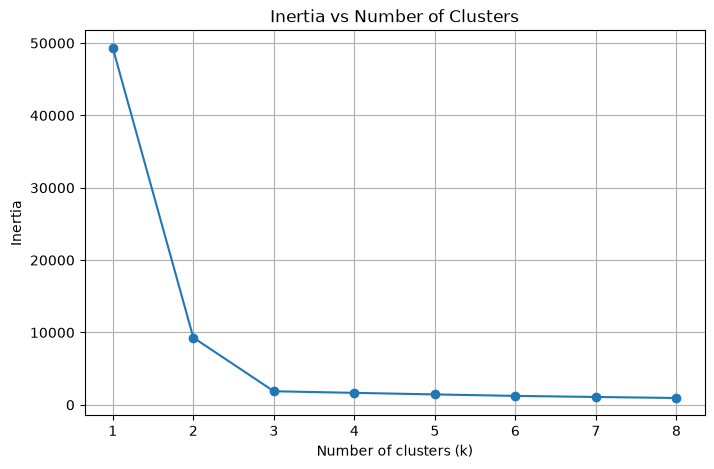

In [5]:
# 1. Run KMeans for different values of k
k_values = range(1, 9)
inertias = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        init="random",
        random_state=0
    )

    kmeans.fit(X)
    inertias.append(kmeans.inertia_)


# 2. Plot inertia vs k
def plot_inertia(k_values, inertias):
    plt.figure(figsize=(8, 5))

    plt.plot(k_values, inertias, marker="o")

    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Inertia")
    plt.title("Inertia vs Number of Clusters")

    plt.xticks(k_values)
    plt.grid()

    plt.show()
    
plot_inertia(k_values, inertias)



### 1.6 The "Elbow Rule" for choosing k

As we increase the number of clusters `k`, the inertia (within-cluster SSE) always decreases:
- More clusters → each point is closer to its centroid → smaller inertia.
- At the extreme: 
  - `k = 1` → all points in one cluster (very high inertia).
  - `k = n_samples` → each point is its own cluster (inertia = 0).

But more clusters are not always better: too many clusters means we are overfitting the noise in the data.

The **Elbow Rule** is a heuristic:
1. Plot inertia vs `k`.  
2. Look for the point where the decrease in inertia slows down sharply — like an elbow in the curve.  
3. That value of `k` is a good trade-off between simplicity (few clusters) and fit (low inertia).

**What to do**
1. For $k \in \{1, \ldots, 10\}$, run `KMeans` and record the inertia.  
2. Plot the inertia values vs `k`.  
3. Inspect the plot and identify where the “elbow” seems to be.  
4. To automate the elbow election, implement a simple knee heuristic pick the `k` with the largest distance from the straight line between (k=1, inertia_1) and (k=max, inertia_max). This corresponds to the place where the curve bends the most: the "elbow."


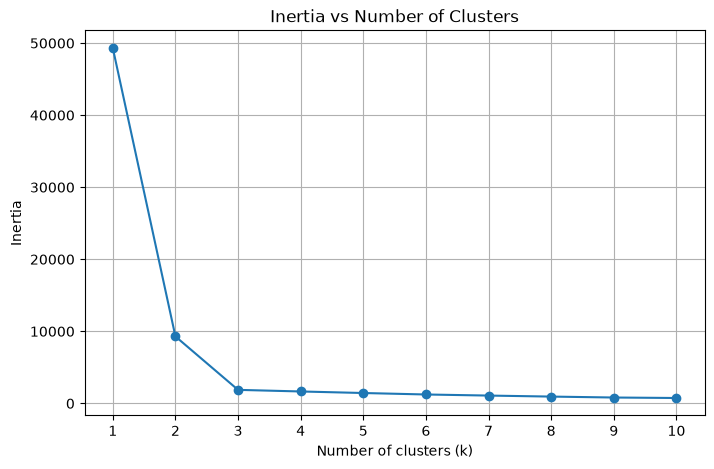

Elbow point: k = 3


In [6]:
import numpy as np
# 1. Run KMeans for k = 1,...,10
k_values = range(1, 11)
inertias = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        init="random",
        random_state=0
    )

    kmeans.fit(X)
    inertias.append(kmeans.inertia_)

# 2. Plot inertia vs k
plot_inertia(k_values, inertias)

# 3. Find the elbow using the maximum distance from the line
def find_elbow(k_values, inertias):
    x1 = k_values[0] # First k value
    y1 = inertias[0] # First inertia value

    x2 = k_values[-1] # Last k value
    y2 = inertias[-1] # Last inertia value

    denominator = np.sqrt((y2 - y1) ** 2 + (x2 - x1) ** 2)

    distances = []

    for i in range(len(k_values)):
        x = k_values[i]
        y = inertias[i]

        # Calculate the distance from the point (x, y) to the line defined by (x1, y1) and (x2, y2)
        # (x1, y1) is the first point, (x2, y2) is the last point, and (x, y) is the current point.
        numerator = abs((y2 - y1) * x - (x2 - x1) * y + x2 * y1 - y2 * x1) 
        distances.append(numerator / denominator)

    elbow_index = np.argmax(distances)

    return k_values[elbow_index]

elbow_k = find_elbow(k_values, inertias)
print(f"Elbow point: k = {elbow_k}")



### 1.7 Validity indices: Silhouette & Davies–Bouldin

The elbow is not always very clear. In some datasets it’s obvious, in others you might need additional validity indices (Silhouette, Davies–Bouldin, etc.). We’ll use Silhouette Score (higher is better, max 1) and Davies–Bouldin (lower is better) to select `k`.

**What to do**
1. For each $k \in \{2, \ldots, 8\}$, run `KMeans` and record the inertia. 
2. Compute `silhouette_score` and `davies_bouldin_score`.
3. Plot both scores vs k and pick your preferred k.


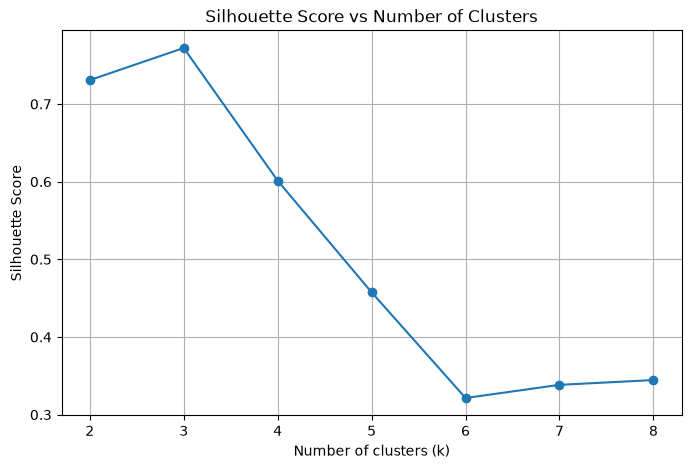

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
# 1. Run KMeans for k = 2,...,8
k_values = range(2, 9)

inertias = []
silhouette_scores = []
davies_bouldin_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        init="random",
        random_state=0
    )

    kmeans.fit(X)

    # Record inertia
    inertias.append(kmeans.inertia_)

    # Compute validity indices
    silhouette_scores.append(
        silhouette_score(X, kmeans.labels_)
    )

    davies_bouldin_scores.append(
        davies_bouldin_score(X, kmeans.labels_)
    )

# 2. Plot Silhouette Score
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs Number of Clusters")

plt.xticks(k_values)
plt.grid()

plt.show()

### 1.8 Scale sensitivity of K-Means

K-Means uses Euclidean distance, so features with larger numeric ranges dominate the distance calculation.  

#### Example
We’ll build a dataset of 3 blobs, then artificially stretch the y-axis by 10.  Without scaling, K-Means will treat the vertical spread as more important, which can change assignments. After applying `StandardScaler`, the clustering goes back to the "intuitive" grouping.  

**What to do**
1. Generate 3 blobs with different spreads (`make_blobs`).
~~~
make_blobs(n_samples=600, centers=[[0,0],[3,0],[0,4]], cluster_std=[1.5, 1.0, 1.0], random_state=42)
~~~
2. Multiply the second coordinate (y-axis) by 10.  
3. Run `KMeans` on:
   - the original data,  
   - the stretched data,  
   - the stretched data after `StandardScaler`.  
4. Plot all three results side by side.  
5. Compare both cluster assignments and inertia values.  
   - Notice how inertia values change simply because distances are rescaled.  
   - More importantly: scaling can change which points belong to which cluster.


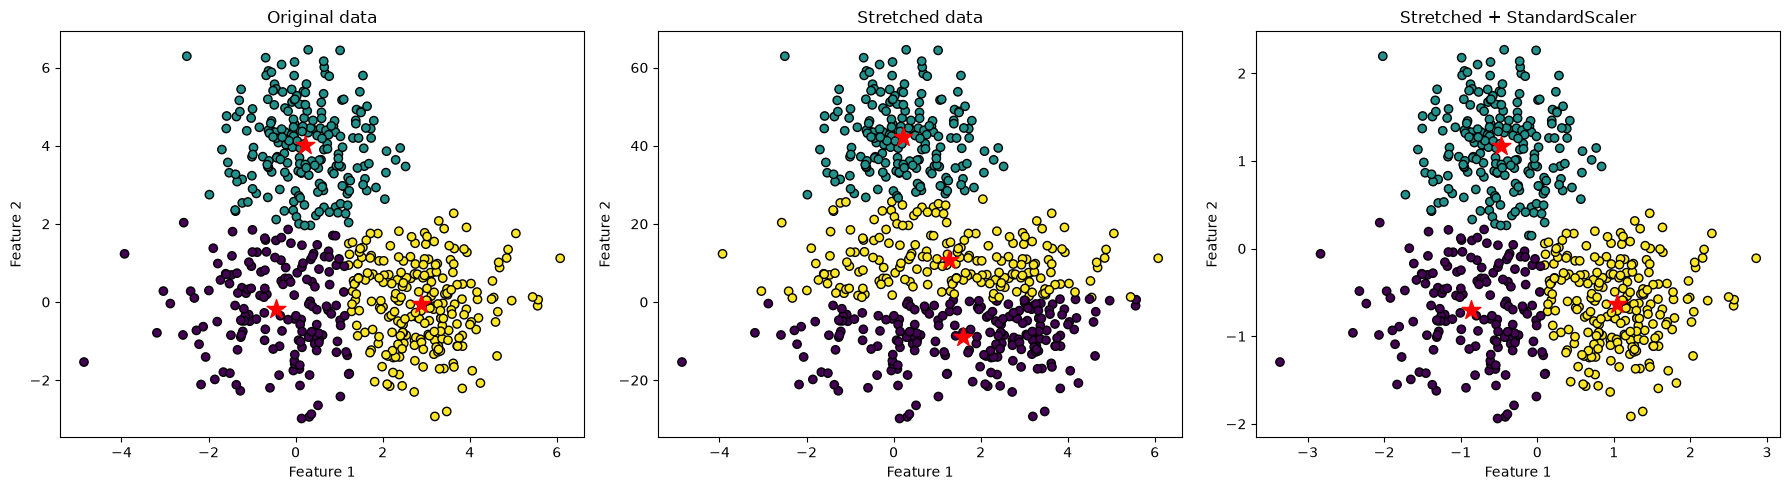

In [8]:
from sklearn.preprocessing import StandardScaler
# 1. Generate the dataset
X, _ = make_blobs(
    n_samples=600,
    centers=[[0, 0], [3, 0], [0, 4]],
    cluster_std=[1.5, 1.0, 1.0],
    random_state=42
)

# 2. Stretch the y-axis by 10
X_stretched = X.copy()
X_stretched[:, 1] *= 10

# 3. Run KMeans on the three datasets

# Original data
kmeans_original = KMeans(
    n_clusters=3,
    n_init=20,
    random_state=0
)
kmeans_original.fit(X)

# Stretched data
kmeans_stretched = KMeans(
    n_clusters=3,
    n_init=20,
    random_state=0
)
kmeans_stretched.fit(X_stretched)

# Stretched data after StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_stretched)

kmeans_scaled = KMeans(
    n_clusters=3,
    n_init=20,
    random_state=0
)
kmeans_scaled.fit(X_scaled)

def plot_clusters(X, kmeans, title, ax):
    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=kmeans.labels_,
        edgecolor="k",
        cmap="viridis"
    )

    ax.scatter(
        kmeans.cluster_centers_[:, 0],
        kmeans.cluster_centers_[:, 1],
        c="red",
        marker="*",
        s=200
    )

    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")


# 4. Plot the three results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_clusters(
    X,
    kmeans_original,
    "Original data",
    axes[0]
)

plot_clusters(
    X_stretched,
    kmeans_stretched,
    "Stretched data",
    axes[1]
)

plot_clusters(
    X_scaled,
    kmeans_scaled,
    "Stretched + StandardScaler",
    axes[2]
)

plt.tight_layout()
plt.show()


### 1.9 Not all datasets are suited for K-Means

K-Means assumes convex, roughly spherical, clusters because it optimizes the sum of squared distances.  
On non-convex shapes (like concentric circles), this kind of clustering technique won't yield a good result.

**What to do**
1. Generate concentric circles with `make_circles(n_samples=600, factor=0.45, noise=0.05, random_state=42)`.  
2. Fit `KMeans` with two clusters and plot the assignments.    
3. Compute the **silhouette score** for K-Means (`silhouette_score(X, labels)`); it should be mediocre despite the obvious ring structure.  

The results motivate trying with hierarchical clustering to attempt at solving the problem.

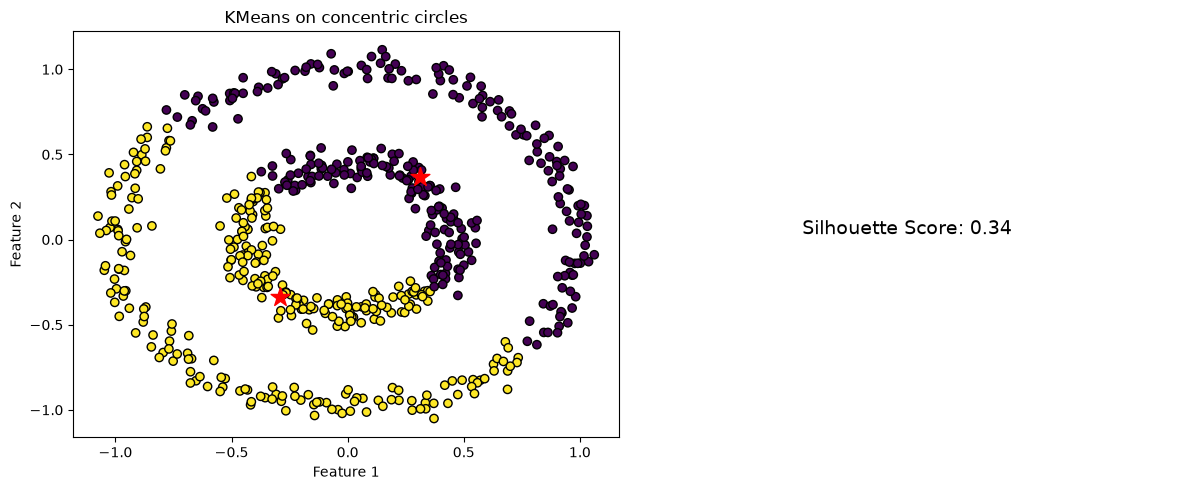

In [9]:
from sklearn.datasets import make_circles
from sklearn.metrics import silhouette_score

# 1. Generate concentric circles
X, _ = make_circles(n_samples=600, factor=0.45, noise=0.05, random_state=42)

kmeans = KMeans(
    n_clusters=2,
    n_init=20,
    random_state=0
)

kmeans.fit(X)

# 2. Plot the clusters
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_clusters(
    X,
    kmeans,
    "KMeans on concentric circles",
    axes[0]
)

# 3. Compute Silhouette Score
silhouette = silhouette_score(X, kmeans.labels_)

axes[1].text(
    0.5,
    0.5,
    f"Silhouette Score: {silhouette:.2f}",
    fontsize=14,
    ha="center"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()



## 2. Agglomerative clustering

### 2.1 Agglomerative clustering on concentric circles

Let’s revisit the circles dataset where K-Means failed.  
Agglomerative (hierarchical) clustering does not assume convex clusters, but the result depends strongly on the linkage criterion. Which one do you think will better solve the problem?

**What to do**
1. Run `AgglomerativeClustering(n_clusters=2, linkage=...)` with linkage = `"single"`, `"complete"`, and `"average"`.  
2. Plot the cluster assignments for each method.  
3. Compare which linkage best recovers the ring structure.  


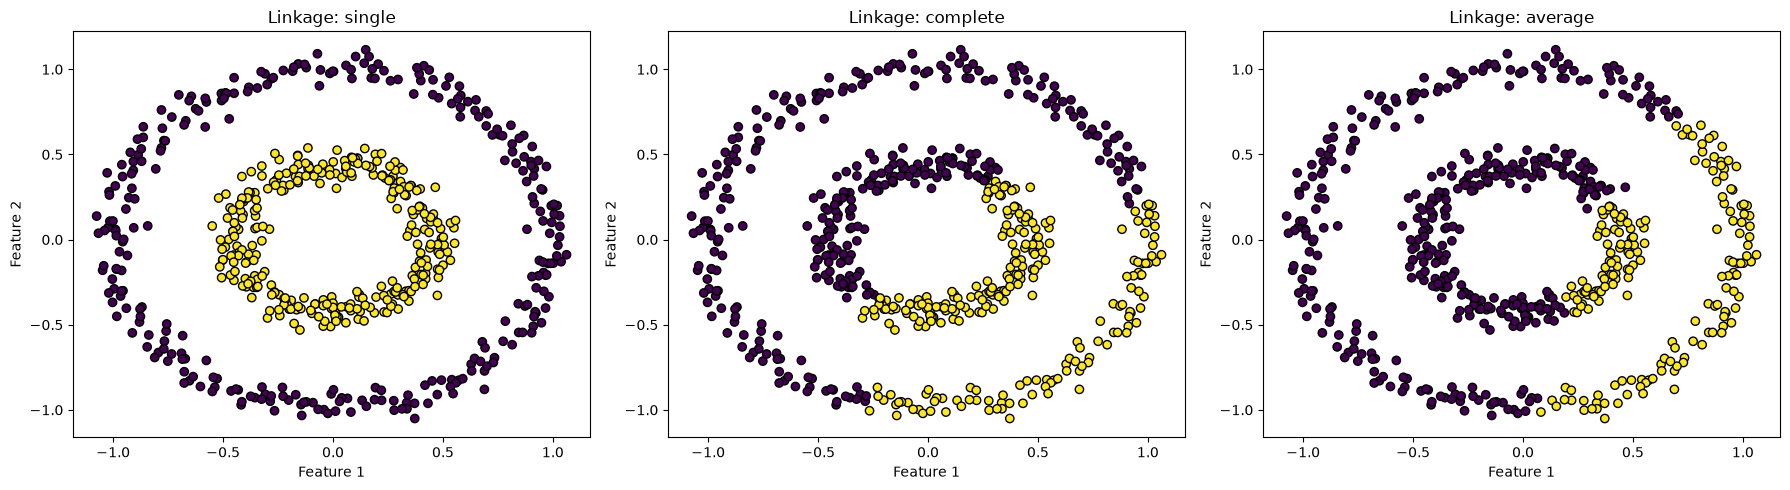

In [10]:
from sklearn.cluster import AgglomerativeClustering
linkages = ["single", "complete", "average"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, linkage in enumerate(linkages):
    clustering = AgglomerativeClustering(
        n_clusters=2,
        linkage=linkage
    )

    labels = clustering.fit_predict(X)

    # 2. Plot the cluster assignments
    axes[i].scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        edgecolor="k",
        cmap="viridis"
    )

    axes[i].set_title(f"Linkage: {linkage}")
    axes[i].set_xlabel("Feature 1")
    axes[i].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

### 2.2 Understanding merges

Single linkage merges clusters based on the minimum pairwise distances. This tends to “chain” neighboring points together, which is perfect for rings.

We can visualize the sequence of merges using a dendrogram:

- Each merge combines two clusters.  
- The vertical axis shows the distance at which the merge happens.  
- In the circles dataset, you’ll see many very small distances at first (neighbors on the ring).  
- Only much later do the two rings merge.

Use the [`dendrogram`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html) from Scipy to plot a compact dendrogram.

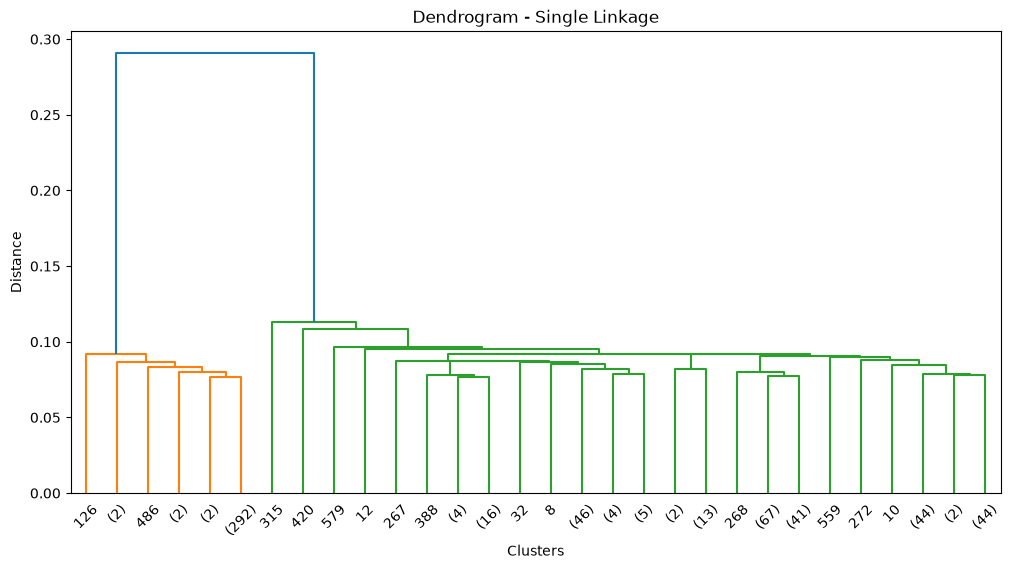

In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Compute the hierarchical clustering using single linkage
Z = linkage(X, method="single")

# 2. Plot a compact dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30
)

plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.title("Dendrogram - Single Linkage")

plt.show()


### 2.3 From dendrogram to clusters

The dendrogram is very useful because it shows the entire sequence of merges in the hierarchy. But usually, we want a flat clustering, assigning each point to one cluster.  
There are two common ways to "cut" the dendrogram:

- Cut by distance threshold: stop merging when the next merge distance exceeds some `t`.  
- Cut by number of clusters: force the hierarchy to stop when exactly `k` clusters remain.

In `AgglomerativeClustering` this is done with the parameter `distance_threshold`. 


**What to do**
1. Run `AgglomerativeClustering` with different values of `t`. Note that you must set `n_clusters=None` when using `distance_threshold`.
2. Look at the dendrogram to choose distance thresholds. Try thresholds like `0.03, 0.09, 0.11, 0.2`.  
3. Plot the results and count how many clusters you get in each case.  

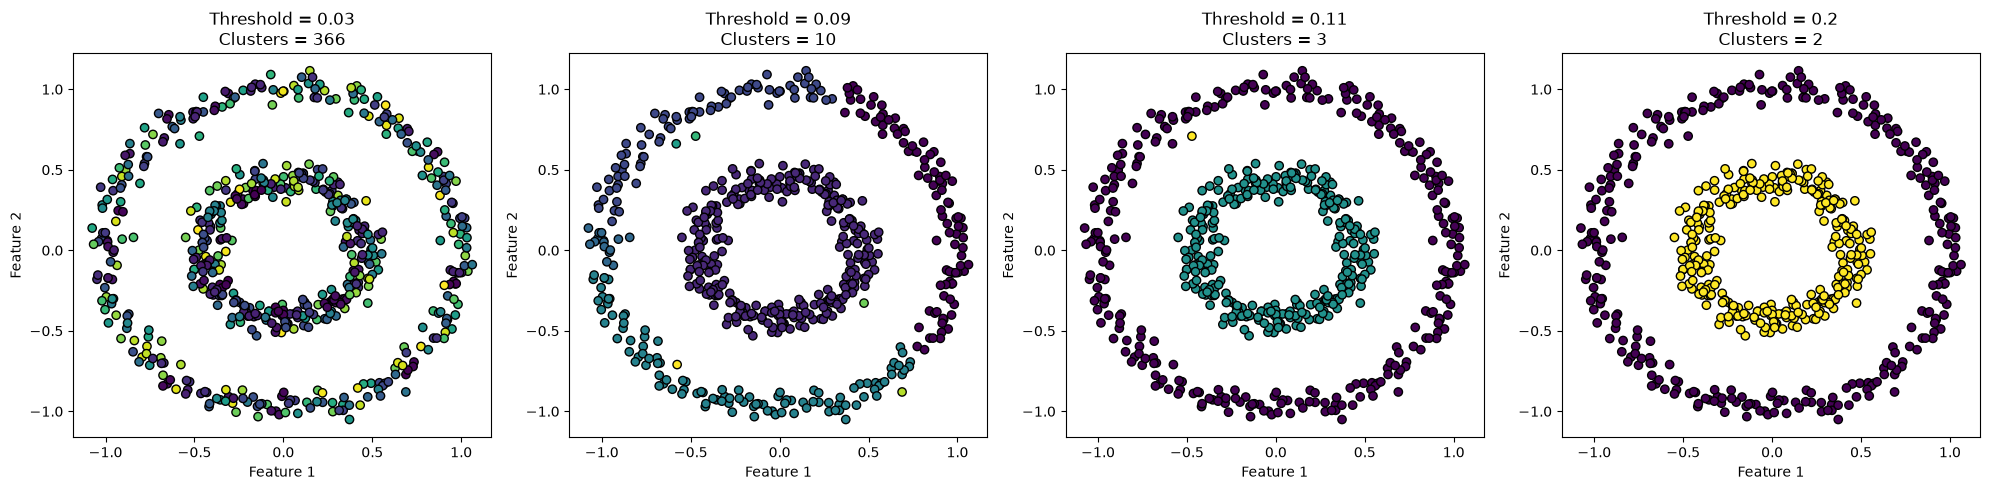

In [12]:
from sklearn.cluster import AgglomerativeClustering

# 1. Run AgglomerativeClustering with different distance thresholds
thresholds = [0.03, 0.09, 0.11, 0.2]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for i, threshold in enumerate(thresholds):
    clustering = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=threshold,
        linkage="single"
    )

    labels = clustering.fit_predict(X)

    n_clusters = len(set(labels))

    # 3. Plot the results
    axes[i].scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        edgecolor="k",
        cmap="viridis"
    )

    axes[i].set_title(
        f"Threshold = {threshold}\n"
        f"Clusters = {n_clusters}"
    )
    axes[i].set_xlabel("Feature 1")
    axes[i].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

### 2.4. (Extra) Comparing clustering algorithms

So far we studied K-Means and Agglomerative in detail, but there are many other clustering algorithms, each with different assumptions (K-Means, Agglomerative, DBSCAN, spectral clustering, Gaussian Mixture Models, etc.). 

The sklearn documentation has a large collection: [Clustering algorithms](https://scikit-learn.org/stable/api/sklearn.cluster.html#module-sklearn.cluster) 

**What to do:**

1. For each of the 2D datasets that we have used, apply several clustering algorithms. 
3. Plot the results (scatter with cluster labels).  
4. Decide which method works best for each dataset, and think why might that be.


In [13]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
def compare_clustering(X, n_clusters):
    algorithms = {
        "K-Means": KMeans(
            n_clusters=n_clusters,
            n_init=20,
            random_state=0
        ),
        "Agglomerative": AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage="single"
        ),
        "DBSCAN": DBSCAN(
            eps=0.2,
            min_samples=5
        ),
        "Gaussian Mixture": GaussianMixture(
            n_components=n_clusters,
            random_state=0
        )
    }

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    for i, (name, algorithm) in enumerate(algorithms.items()):
        labels = algorithm.fit_predict(X)

        axes[i].scatter(
            X[:, 0],
            X[:, 1],
            c=labels,
            edgecolor="k",
            cmap="viridis"
        )

        axes[i].set_title(name)
        axes[i].set_xlabel("Feature 1")
        axes[i].set_ylabel("Feature 2")

    plt.tight_layout()
    plt.show()

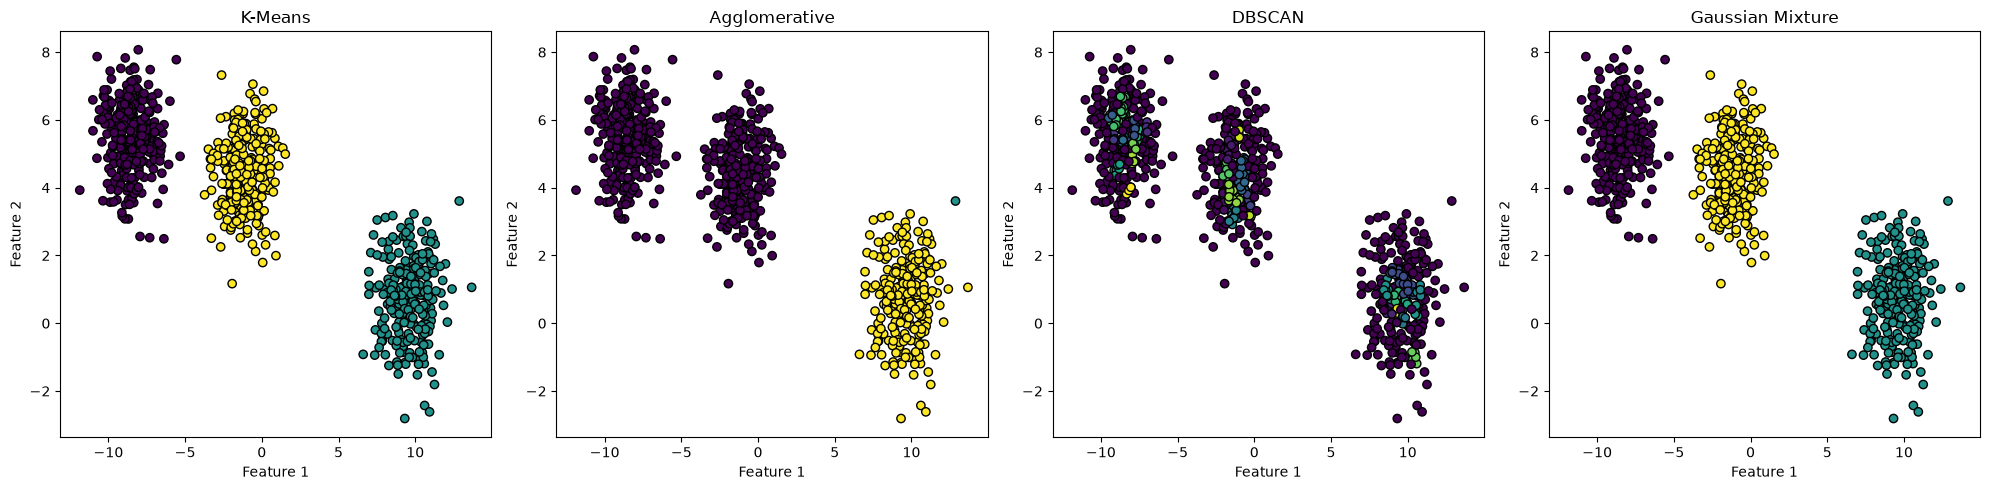

In [14]:
# Generate blobs
X_blobs, _ = make_blobs(
    n_samples=800,
    centers=3,
    cluster_std=1.1,
    random_state=7
)

compare_clustering(X_blobs, 3)

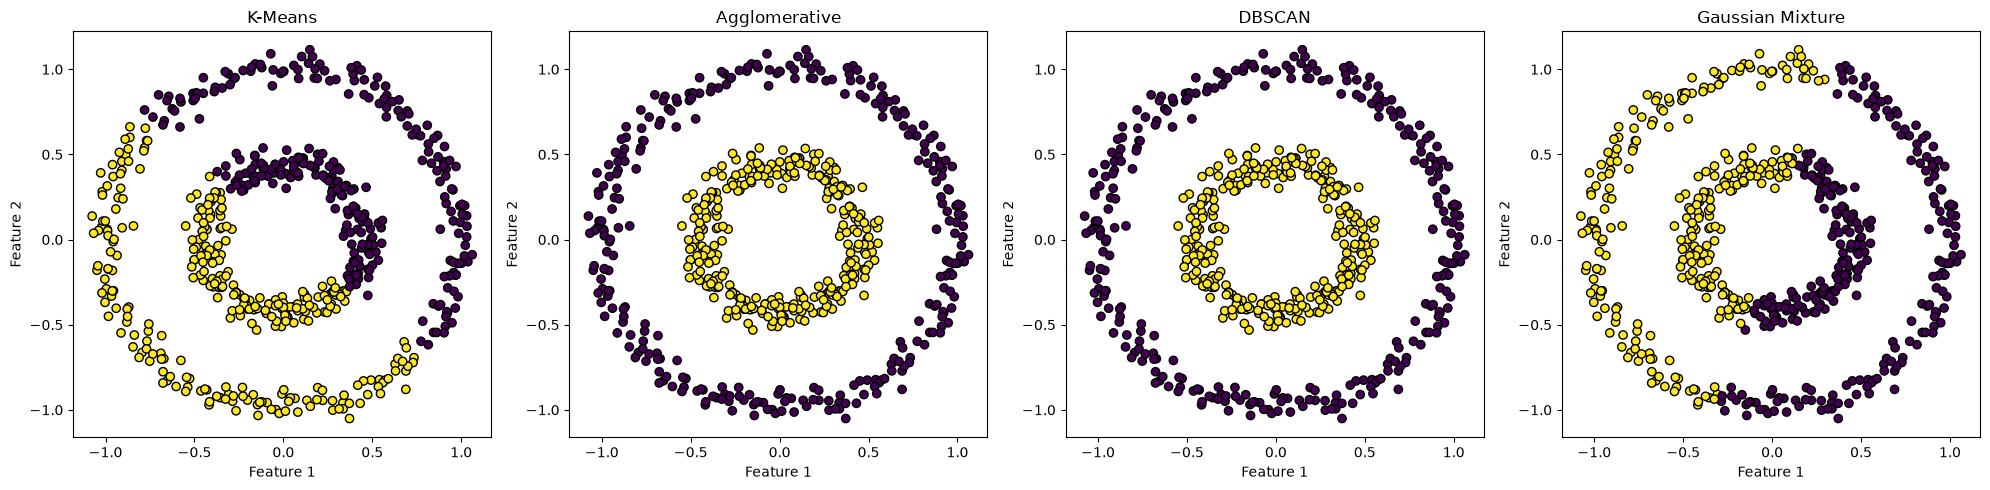

In [15]:
# Generate concentric circles
X_circles, _ = make_circles(
    n_samples=600,
    factor=0.45,
    noise=0.05,
    random_state=42
)

compare_clustering(X_circles, 2)

4. Decide which method works best for each dataset, and think why might that be.

# Solution

- **Blobs:** **K-Means** works best. The clusters are compact, roughly spherical, and separated, which matches K-Means' Euclidean-distance and centroid-based assumptions. Gaussian Mixture should also perform well because it can model elliptical Gaussian clusters, while DBSCAN depends more strongly on the choice of `eps`.

- **Concentric circles:** **DBSCAN** works best with suitable `eps` and `min_samples`. It groups points by density and can recover non-convex ring shapes, unlike K-Means, which divides the data using distance to centroids. Single-linkage agglomerative clustering can also recover the rings because its chaining behavior follows neighboring points, but it is more sensitive to noise and the distance threshold.